In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/telco_churn.csv")

# EDA-only fixes (the real, pipeline-based cleaning happens in Phase 4)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

overall = df["ChurnFlag"].mean() * 100
print(f"Overall churn rate: {overall:.1f}%")

Overall churn rate: 26.5%


In [2]:
def churn_by(col, order=None, save_as=None, rotate=0):
    rate = (df.groupby(col)["ChurnFlag"].mean() * 100).round(1)
    if order:
        rate = rate.reindex(order)
    print(rate.to_frame("churn_rate_%"))

    ax = rate.plot(kind="bar", figsize=(7, 4), color="steelblue")
    ax.axhline(overall, color="red", linestyle="--", label=f"Overall {overall:.1f}%")
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(f"Churn rate by {col}")
    ax.legend()
    plt.xticks(rotation=rotate)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    if save_as:
        plt.savefig(f"../reports/{save_as}.png", dpi=150, bbox_inches="tight")
    plt.show()

                churn_rate_%
Contract                    
Month-to-month          42.7
One year                11.3
Two year                 2.8


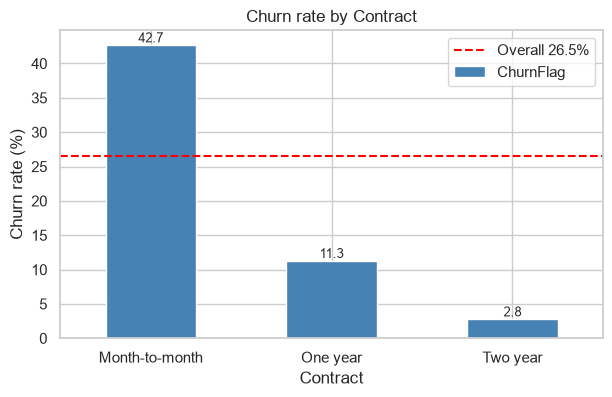

In [3]:
churn_by("Contract", order=["Month-to-month", "One year", "Two year"],
         save_as="churn_by_contract")

                 churn_rate_%
InternetService              
DSL                      19.0
Fiber optic              41.9
No                        7.4


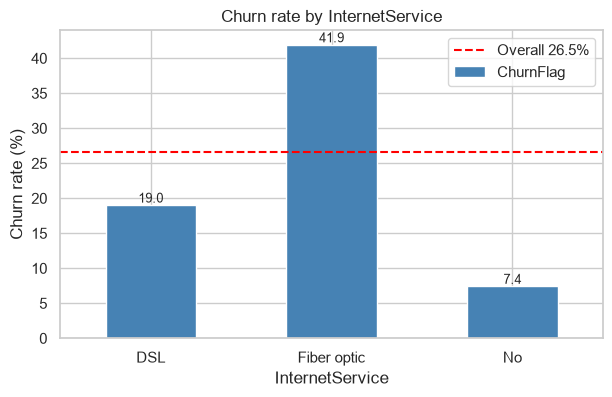

                     churn_rate_%
TechSupport                      
No                           41.6
No internet service           7.4
Yes                          15.2


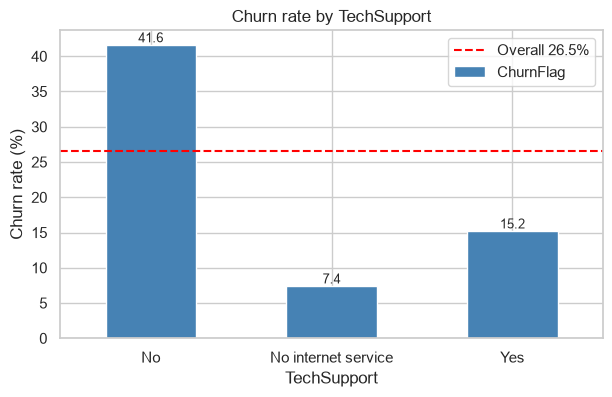

                     churn_rate_%
OnlineSecurity                   
No                           41.8
No internet service           7.4
Yes                          14.6


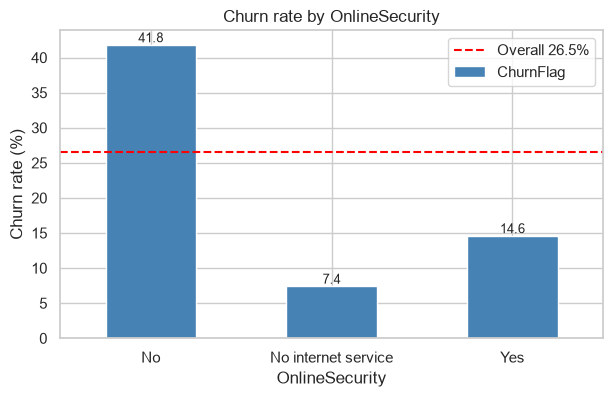

In [4]:
churn_by("InternetService", save_as="churn_by_internet")
churn_by("TechSupport", save_as="churn_by_techsupport")
churn_by("OnlineSecurity", save_as="churn_by_onlinesecurity")

                           churn_rate_%
PaymentMethod                          
Bank transfer (automatic)          16.7
Credit card (automatic)            15.2
Electronic check                   45.3
Mailed check                       19.1


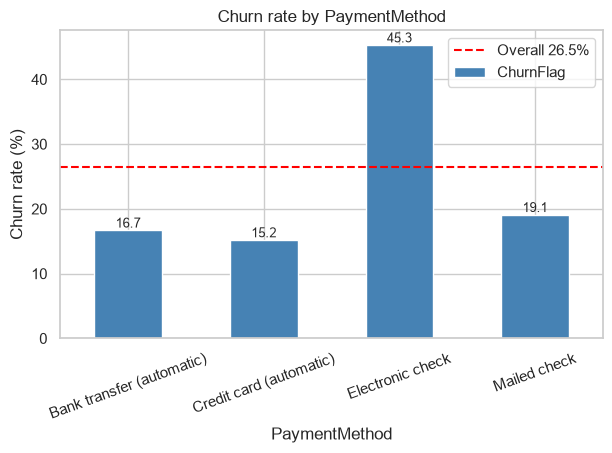

                  churn_rate_%
PaperlessBilling              
No                        16.3
Yes                       33.6


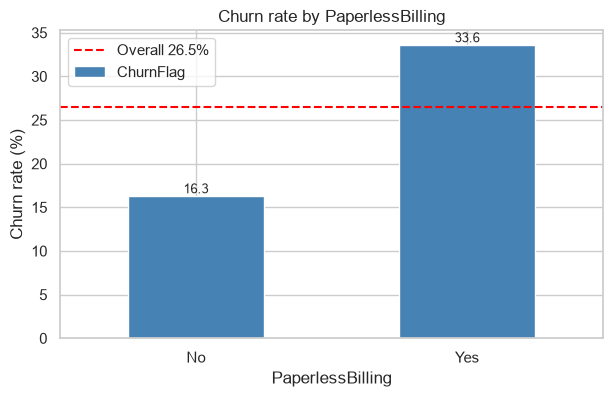

In [5]:
churn_by("PaymentMethod", save_as="churn_by_payment", rotate=20)
churn_by("PaperlessBilling", save_as="churn_by_paperless")

               churn_rate_%
SeniorCitizen              
0                      23.6
1                      41.7


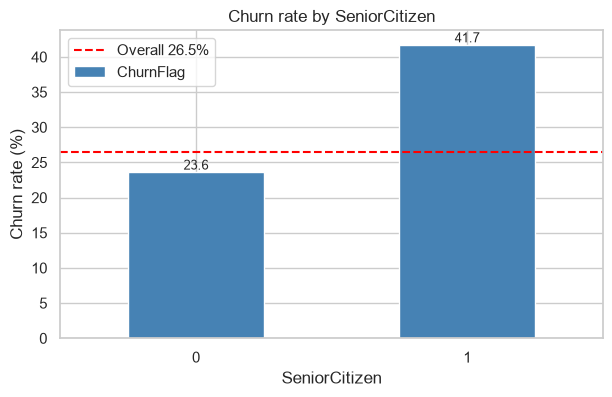

         churn_rate_%
Partner              
No               33.0
Yes              19.7


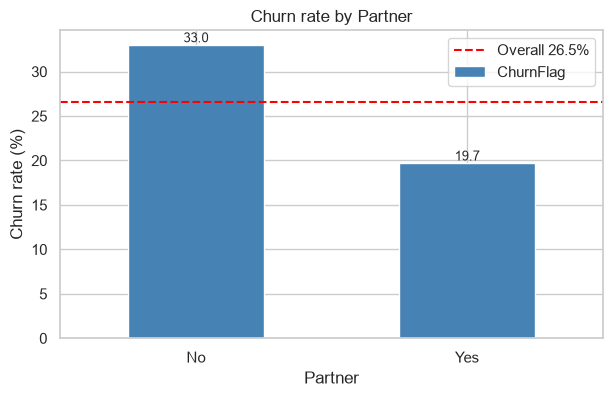

            churn_rate_%
Dependents              
No                  31.3
Yes                 15.5


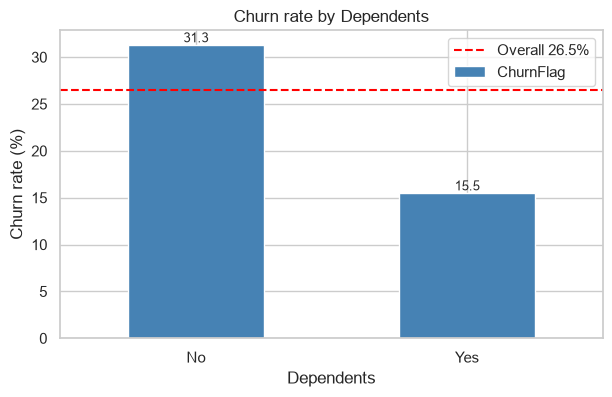

        churn_rate_%
gender              
Female          26.9
Male            26.2


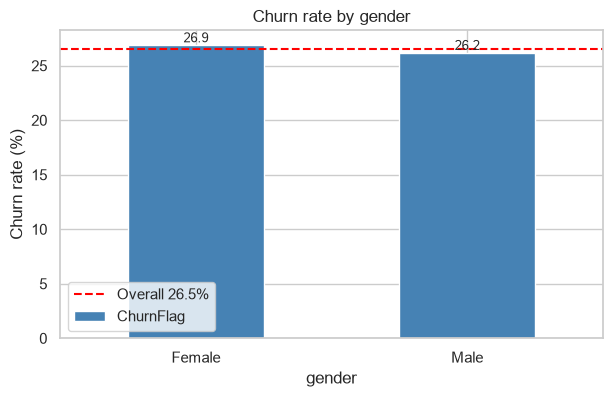

In [6]:
churn_by("SeniorCitizen", save_as="churn_by_senior")
churn_by("Partner")
churn_by("Dependents")
churn_by("gender")

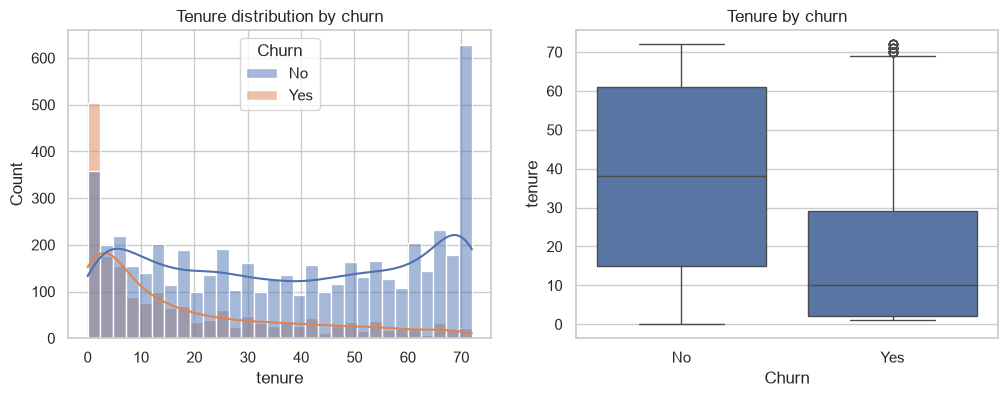

             churn_rate_%
TenureGroup              
0-12                 47.4
13-24                28.7
25-48                20.4
49-72                 9.5


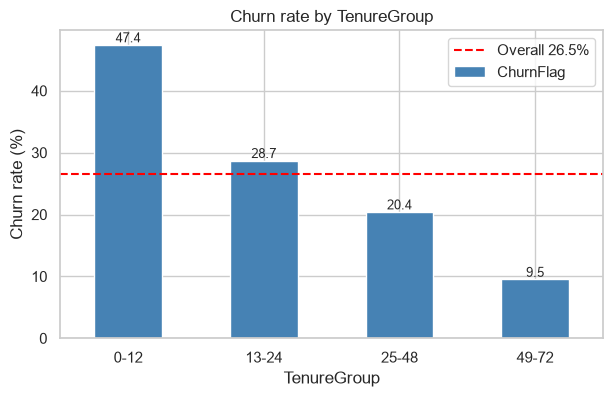

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Tenure distribution by churn")

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[1])
axes[1].set_title("Tenure by churn")

plt.savefig("../reports/tenure_vs_churn.png", dpi=150, bbox_inches="tight")
plt.show()

# Churn rate by tenure group
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12", "13-24", "25-48", "49-72"])
churn_by("TenureGroup", save_as="churn_by_tenure_group")

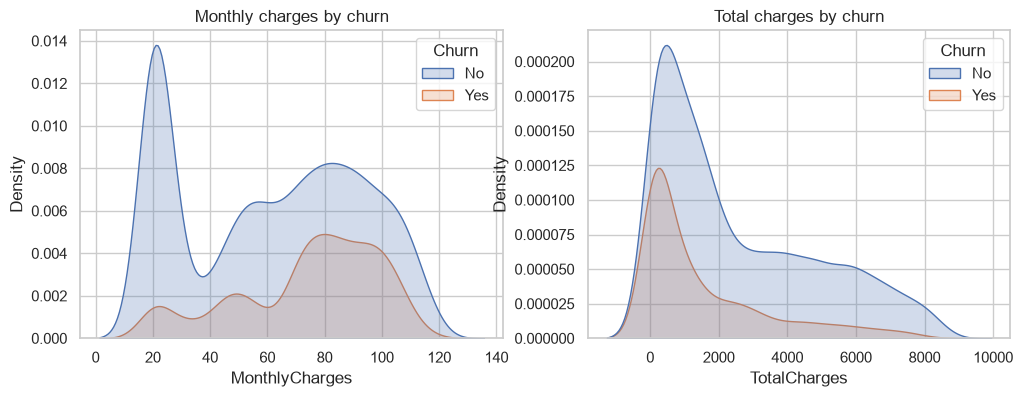

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       37.6            61.3        2549.9
Yes      18.0            74.4        1531.8


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", fill=True, ax=axes[0])
axes[0].set_title("Monthly charges by churn")

sns.kdeplot(data=df, x="TotalCharges", hue="Churn", fill=True, ax=axes[1])
axes[1].set_title("Total charges by churn")

plt.savefig("../reports/charges_vs_churn.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean().round(1))

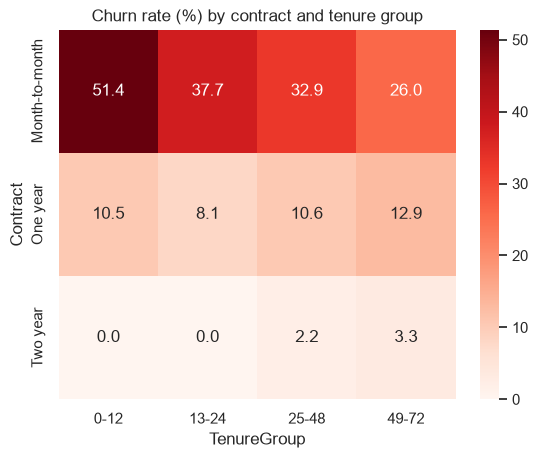

In [9]:
pivot = df.pivot_table(index="Contract", columns="TenureGroup",
                       values="ChurnFlag", aggfunc="mean", observed=True).mul(100).round(1)

sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn rate (%) by contract and tenure group")
plt.savefig("../reports/churn_contract_tenure_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

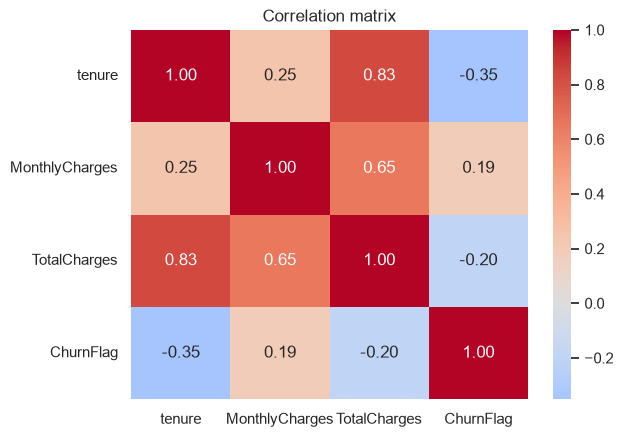

In [10]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.savefig("../reports/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
cat_cols = df.select_dtypes(include="object").columns.drop(["customerID", "Churn"])
spread = {c: (df.groupby(c)["ChurnFlag"].mean().max() - df.groupby(c)["ChurnFlag"].mean().min()) * 100
          for c in cat_cols}
pd.Series(spread).sort_values(ascending=False).round(1).to_frame("churn_rate_spread_%")

C:\Users\PADMAVATHI\AppData\Local\Temp\ipykernel_21220\4054373536.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.drop(["customerID", "Churn"])


,churn_rate_spread_%
Contract,39.9
InternetService,34.5
OnlineSecurity,34.4
TechSupport,34.2
OnlineBackup,32.5
DeviceProtection,31.7
PaymentMethod,30.0
StreamingMovies,26.3
StreamingTV,26.1
PaperlessBilling,17.2
